In [1]:
import torch
import os
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
import numpy as np
import random
sys.path.append('..')

from models.cifar_encoder_classifier import CIFAR10EncoderClassifier
from trainers.encoder_classifier_trainer import EncoderClassifierTrainer


In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)  

In [3]:
data_path = os.path.join("..", "data")
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=20),
    transforms.RandomAffine(0, translate=(0.2, 0.2)),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()

Files already downloaded and verified
Files already downloaded and verified
Epoch [1] - Train Loss: 1.6784, Train Acc: 0.3819
Epoch [1] - Val Loss: 1.4328, Val Acc: 0.4784, Test Acc: 0.4850
Epoch [2] - Train Loss: 1.4265, Train Acc: 0.4765
Epoch [2] - Val Loss: 1.3793, Val Acc: 0.4993, Test Acc: 0.5126
Epoch [3] - Train Loss: 1.3013, Train Acc: 0.5268
Epoch [3] - Val Loss: 1.1762, Val Acc: 0.5758, Test Acc: 0.5788
Epoch [4] - Train Loss: 1.2224, Train Acc: 0.5577
Epoch [4] - Val Loss: 1.2962, Val Acc: 0.5561, Test Acc: 0.5551
Epoch [5] - Train Loss: 1.1566, Train Acc: 0.5866
Epoch [5] - Val Loss: 1.1885, Val Acc: 0.5780, Test Acc: 0.5636
Epoch [6] - Train Loss: 1.1080, Train Acc: 0.6058
Epoch [6] - Val Loss: 0.9759, Val Acc: 0.6516, Test Acc: 0.6485
Epoch [7] - Train Loss: 1.0606, Train Acc: 0.6227
Epoch [7] - Val Loss: 1.0323, Val Acc: 0.6362, Test Acc: 0.6358
Epoch [8] - Train Loss: 1.0251, Train Acc: 0.6350
Epoch [8] - Val Loss: 0.9838, Val Acc: 0.6515, Test Acc: 0.6593
Epoch [9] - 

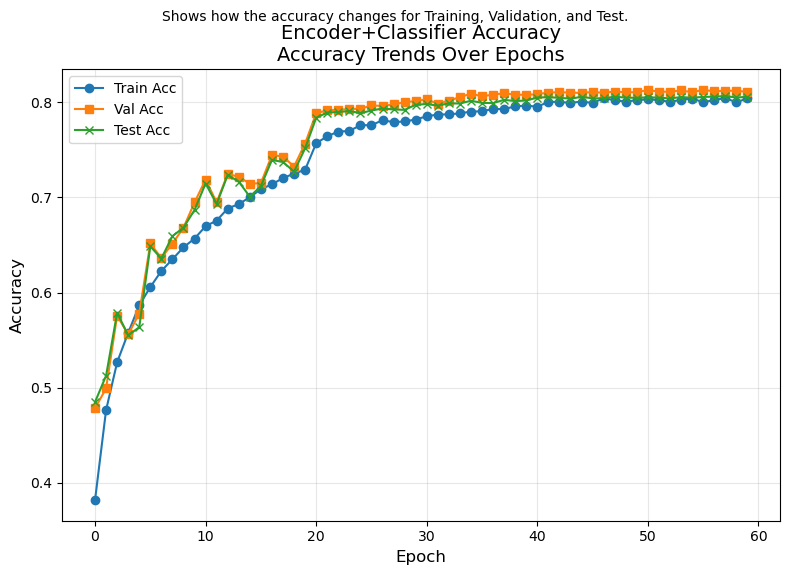

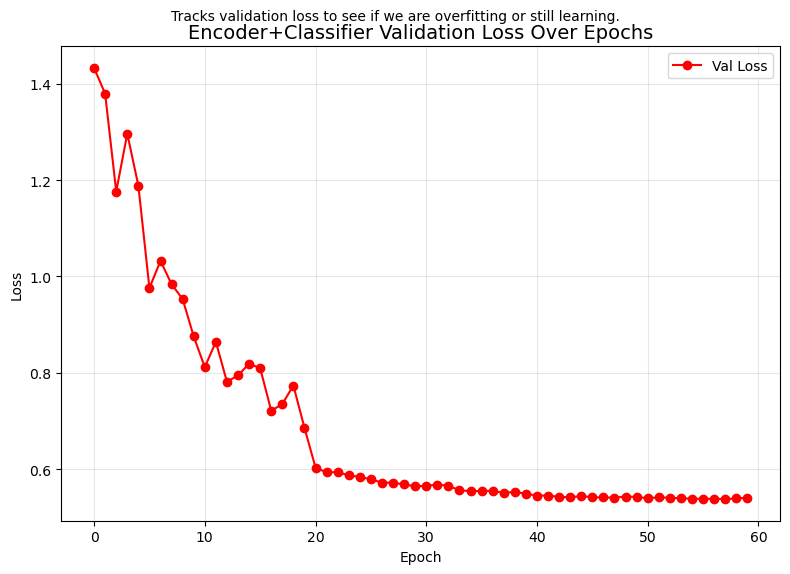

=== Final Encoder+Classifier Metrics ===
Val Loss: 0.5405
Train Acc: 80.41%
Val   Acc: 81.09%
Test  Acc: 80.56%


In [7]:
full_train_dataset = datasets.CIFAR10(root=data_path, train=True, download=True)
test_dataset   = datasets.CIFAR10(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)


model = CIFAR10EncoderClassifier(
input_shape=(3, 32, 32),
channels=[64, 128, 256], 
kernel_sizes=[3, 3, 3],
strides=[2, 2, 2],
paddings=[1, 1, 1],
hidden_dims=[1024],
dropout_conv=0.0,
dropout_fc=0.1,
batch_norm_fc=True,
batch_norm_conv=True,
latent_dim=128,
num_classes=10
)
trainer = EncoderClassifierTrainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader = test_loader,
    device='cuda',
    lr=5e-4,
    num_epochs=60,
    weight_decay=3e-5,
    scheduler_type="step", 
    step_size=20,
    early_stopping=True,
    patience=5
)
trainer.train()
trainer.plot_metrics()

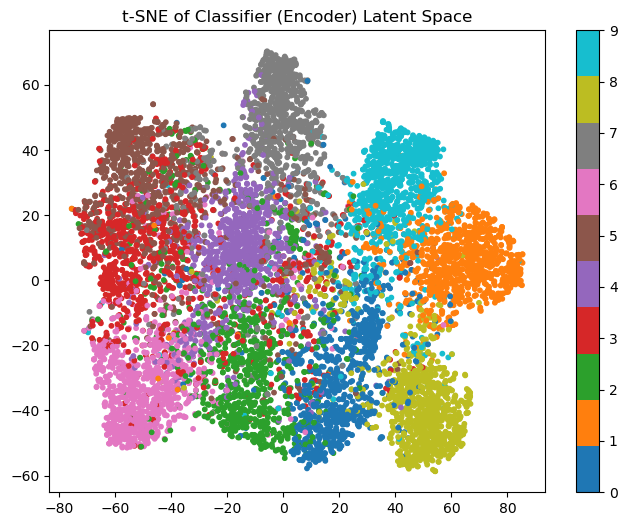

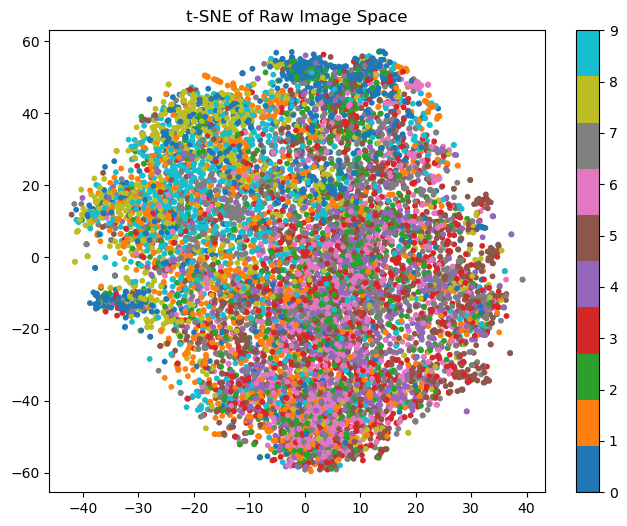

In [8]:
from utils import plot_tsne_classifier
plot_tsne_classifier(model, test_loader, device='cuda')